# Emulating a chaotic system — and catching it when it lies

A small neural network is trained to imitate the **Lorenz-63** equations, the standard
model of deterministic chaos. Then eight measurements ask whether it reproduces the
*dynamics* of the system, not just its next state.

The notebook builds everything from the equations up. By the end you will have watched a
model reach low one-step error while getting the dynamics wrong, located where it goes
wrong, and fixed it.

| section | what happens |
|---|---|
| 1–3 | the system, why prediction fails, and the one quantity that is exactly known |
| 4 | two ways to build an emulator |
| 5 | eight diagnostics, and what a good score looks like |
| 6 | why the failure happens, and the repair |

**Running on a GPU.** This code is plain JAX, so it uses a GPU automatically when one is
visible. On Colab: `Runtime → Change runtime type → GPU`, then

```python
!pip install -U "jax[cuda12]" equinox optax
```

The cell below prints which device it picked. Training stays in float32 for speed; the
diagnostics run in float64, and section 7 shows why that distinction is worth keeping.

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import lorenz
import train
import diagnostics as diag

print(train.describe_device())
print("jax", jax.__version__)

# float64 for every diagnostic; train.cast() raises rather than silently
# truncating if that ever becomes unavailable
train.setup()
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (9, 3.2)})

JAX backend: cpu | devices: [CpuDevice(id=0)] | x64 available: True
(running on CPU -- the same code selects the GPU automatically if one is visible)
jax 0.11.2


## 1. The system

$$
\dot x = \sigma (y - x), \qquad
\dot y = x (\rho - z) - y, \qquad
\dot z = x y - \beta z
$$

with $\sigma = 10$, $\rho = 28$, $\beta = 8/3$. There is no randomness anywhere. The
variables are not positions in space; they are abstract amplitudes (roughly, temperature
contrasts and circulation strength), which is all that matters here: three numbers obeying a
simple, exact rule.

Integrate them and the trajectory traces a fixed shape forever — the **attractor**. That
shape is reproducible even though individual paths are not, and that distinction is what this
notebook is about.

trajectory shape: (20000, 3)
range  x: -18.1 .. 18.9


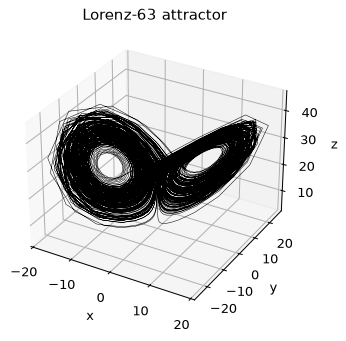

In [ ]:
y0 = jnp.array([1.0, 1.0, 1.0])
gt = lorenz.trajectory(y0, 20_000, burn_in=1_000)   # drop the transient
print("trajectory shape:", gt.shape)
print("range  x: %.1f .. %.1f" % (gt[:, 0].min(), gt[:, 0].max()))

fig = plt.figure(figsize=(4.5, 4.2))
ax = fig.add_subplot(111, projection="3d")
ax.plot(*[gt[::5, i] for i in range(3)], lw=0.4, color="black")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title("Lorenz-63 attractor")
plt.show()

## 2. Why pointwise prediction fails

Two runs started a hair apart separate exponentially: $\delta(t) \approx \delta(0) e^{\lambda_1 t}$
with $\lambda_1 \approx 0.9$ per unit time. An initial separation of $10^{-6}$ grows by
$e^{0.9 \times 50} \approx 10^{19}$ over 50 time units — vastly more than the attractor's
~40-unit width. **After roughly one time unit the two trajectories are unrelated.**

So a plot of predicted-vs-true position beyond a short horizon does not measure skill; the
error has saturated at the size of the attractor and merely wanders. That is the first reason
we need different measurements.

The numbers below are what "$\lambda_1 \approx 0.9$" means in practice, computed from the
trajectory rather than quoted:

* $\lambda_1 > 0$ — the chaos (stretching)
* $\lambda_2 = 0$ — neutral, along the flow
* $\lambda_3 < 0$ — strong contraction

Lyapunov spectrum of the ground truth
  lambda_1     +0.883
  lambda_2     +0.000
  lambda_3    -14.550
  sum         -13.667
  textbook   (0.9056, 0.0, -14.5723)
  convergence slope of lambda_1: -1.57e-05  (0 = converged)


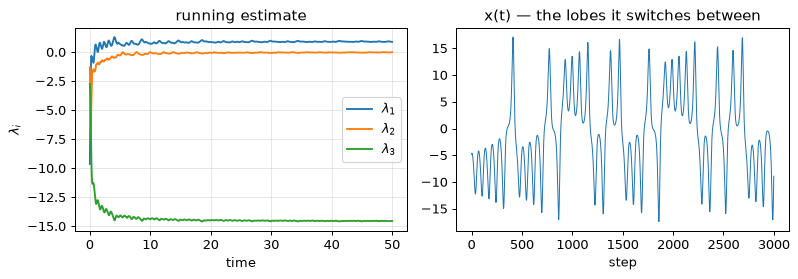

error-growth rate 0.977  (vs lambda_1 0.883)


In [ ]:
gt_step = lambda y: lorenz.rk4_step(y)          # the true one-step map

start = gt[0]          # a state on the attractor, NOT the raw [1,1,1] seed
lam, running = diag.lyapunov_spectrum(gt_step, start, steps=5_000)
print("Lyapunov spectrum of the ground truth")
for k in ("lambda_1", "lambda_2", "lambda_3", "sum"):
    print(f"  {k:10s} {float(lam[k]):+8.3f}")
print(f"  textbook   {lorenz.TEXTBOOK_LYAPUNOV}")
print(f"  convergence slope of lambda_1: {float(lam['slope_lambda_1']):+.2e}  (0 = converged)")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
axs[0].plot(jnp.arange(1, running.shape[0] + 1) * lorenz.DT, running)
axs[0].set_xlabel("time"); axs[0].set_ylabel(r"$\lambda_i$")
axs[0].set_title("running estimate")
axs[0].legend([r"$\lambda_1$", r"$\lambda_2$", r"$\lambda_3$"])
axs[0].grid(alpha=.3)
axs[1].plot(gt[:3000, 0], lw=0.8)
axs[1].set_xlabel("step"); axs[1].set_title("x(t) — the lobes it switches between")
plt.tight_layout(); plt.show()

# independent check: follow two nearby states instead of differentiating
eg, _ = diag.error_growth(gt_step, start)
print(f"error-growth rate {float(eg['growth_rate']):.3f}  (vs lambda_1 {float(lam['lambda_1']):.3f})")

## 3. The one quantity that is exactly known

Take a small blob of initial conditions. It is stretched in some directions and squashed in
others; its **volume** changes at a rate equal to the divergence of the field,
$\nabla\cdot f$. For Lorenz-63 that is a constant:

$$
\nabla\cdot f = -(\sigma + 1 + \beta) = -13.667 \quad\text{at every point in space.}
$$

Two consequences make this the backbone of everything that follows:

1. The three Lyapunov exponents must **sum** to it: $0.906 + 0 + (-14.57) = -13.66$.
2. When testing an emulator, the target is a *known number at each state*. Any departure is
   the model's error, with nothing to argue about.

The cell below measures it from the trajectory, using autodiff of one step rather than a
hand-derived formula.

volume-change rate of the true system, per state:
  mean  -13.666566   (divergence -13.666667)
  std   9.10e-05      <- constant, up to round-off
  ratio 0.99999263


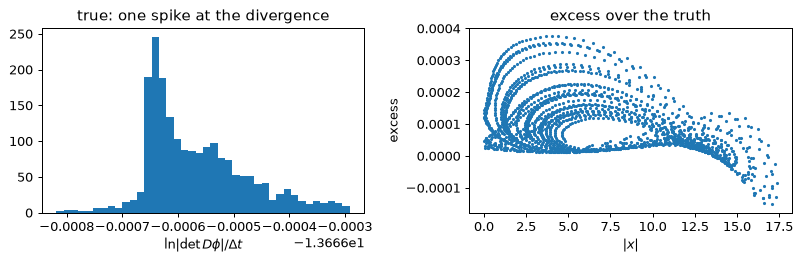

In [ ]:
probe = lorenz.trajectory(y0, 2_000, burn_in=1_000)     # states on the attractor
lc, lc_arr = diag.local_contraction(gt_step, probe)

print("volume-change rate of the true system, per state:")
print(f"  mean  {float(lc['rate_mean']):+.6f}   (divergence {lorenz.DIVERGENCE:+.6f})")
print(f"  std   {float(lc['rate_std']):.2e}      <- constant, up to round-off")
print(f"  ratio {float(lc['ratio']):.8f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(lc_arr["rate"], bins=40, color="tab:blue")
ax[0].set_xlabel(r"$\ln|\det D\phi|/\Delta t$")
ax[0].set_title("true: one spike at the divergence")
ax[1].plot(lc_arr["abs_x"], lc_arr["excess"], ".", ms=3)
ax[1].set_xlabel(r"$|x|$"); ax[1].set_ylabel("excess"); ax[1].set_title("excess over the truth")
plt.tight_layout(); plt.show()

## 4. Two ways to build an emulator

Both learn the *same* object — one step of the flow — with the same network, the same
optimiser and the same data. The only difference is where the physics lives.

| | what is learned | volume change is |
|---|---|---|
| **map** | $x_{n+1} = f(x_n)$ | emergent, from $\det Df$ — no single local quantity |
| **field** | $\dot x = g(x)$, integrated with RK4 | $\nabla\cdot g$ — a first derivative of the output |

That difference is the whole argument of section 6.

In [ ]:
data = train.make_dataset(jax.random.PRNGKey(0), n_traj=4, steps=3_000,
                          burn_in=1_000, noise=0.05)
print("training pairs :", data["x"].shape)
print("test trajectory:", data["test_traj"].shape)
print(f"input noise    : {data['noise']}   (added to inputs only; targets stay clean)")
print("dtype          :", data["x"].dtype)

training pairs : (11996, 3)
test trajectory: (3000, 3)
input noise    : 0.05   (added to inputs only; targets stay clean)
dtype          : float32


In [ ]:
import equinox as eqx

key = jax.random.PRNGKey(1)
map_model = train.make_mlp(key, width=64, depth=2)
field_model = train.make_mlp(jax.random.PRNGKey(2), width=64, depth=2)

n_params = sum(a.size for a in jax.tree_util.tree_leaves(eqx.filter(map_model, eqx.is_array)))
print("parameters per model:", n_params)

step_map = train.make_step("map", map_model)
step_field = train.make_step("field", field_model)

# same architecture, different meaning: a map jumps, a field is integrated
y = jnp.array([1.0, 2.0, 3.0])
print("map step  :", step_map(y))
print("field step:", step_field(y))

parameters per model: 4611


map step  : [-0.0596623   0.19273241  0.23663842]


field step: [0.99838091 2.0017502  3.0000625 ]


Training is plain Adam on mean squared error of the next state. `train.py` also has an
optional penalty on the field's divergence, used later; it is switched off for now.

epoch   0 | mse 91.121933 | divergence penalty 0.0000


epoch  10 | mse 0.014778 | divergence penalty 0.0000


epoch  20 | mse 0.021398 | divergence penalty 0.0000


epoch  30 | mse 0.009826 | divergence penalty 0.0000


epoch  39 | mse 0.009324 | divergence penalty 0.0000


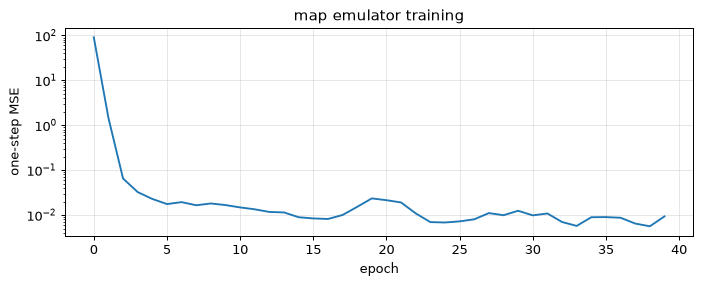

one-step MSE (float64): 0.01049


In [ ]:
map_model, map_hist = train.train("map", map_model, data, key, epochs=40, batch=256)

fig, ax = plt.subplots(figsize=(9, 3))
ax.semilogy([h["mse"] for h in map_hist])
ax.set_xlabel("epoch"); ax.set_ylabel("one-step MSE"); ax.set_title("map emulator training")
ax.grid(alpha=.3); plt.show()

step_map = train.make_step("map", train.cast(map_model, train.DTYPE_DIAG))
print("one-step MSE (float64): %.5f" % train.final_mse(data, step_map))

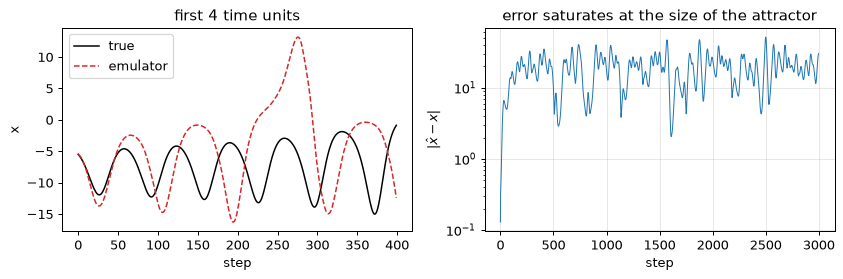

mean |error| over the whole run: 18.76
attractor bounding-box diagonal: 67.03


In [ ]:
# roll the emulator forward from the same initial condition as the truth
ref = data["test_traj"]
emu = train.rollout(step_map, data["test_ic"], ref.shape[0] - 1)
err = jnp.linalg.norm(emu - ref[1:], axis=1)

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2))
axs[0].plot(ref[:400, 0], color="black", lw=1.2, label="true")
axs[0].plot(emu[:400, 0], color="tab:red", lw=1.2, ls="--", label="emulator")
axs[0].set_xlabel("step"); axs[0].set_ylabel("x"); axs[0].legend()
axs[0].set_title("first 4 time units")
axs[1].plot(err, lw=0.8)
axs[1].set_yscale("log"); axs[1].set_xlabel("step"); axs[1].set_ylabel(r"$|\hat x - x|$")
axs[1].set_title("error saturates at the size of the attractor"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("mean |error| over the whole run: %.2f" % float(err.mean()))
print("attractor bounding-box diagonal: %.2f" % float(jnp.linalg.norm(ref.max(0) - ref.min(0))))

The error starts small and then stops growing — it has hit the attractor's width. Past that
point the number is a property of the attractor, not of the emulator. **It cannot tell us
whether the dynamics are right**, which is why the next section measures something else.

## 5. The diagnostics

Each takes a one-step function and returns numbers. None of them plots or decides pass/fail;
that happens here, with the controls visible.

| diagnostic | question |
|---|---|
| `lyapunov_spectrum` | how fast does it stretch and squash? |
| `local_contraction` | **where** is the volume change wrong? |
| `error_growth` | how fast do two nearby states separate? (independent of the spectrum) |
| `invariant_measure` | does it visit the same regions? |
| `correlation_dimension` | is its attractor the right shape? |
| `symbolic_dynamics` | does it switch lobes as often? |
| `dmd_spectrum` | does its oscillation content match? |
| `vector_field_slice` | does its local rule match off the training data? |

**Controls.** A number with no reference is not a measurement. So every diagnostic is also
run on:

* **a second true trajectory** from a different initial condition — the *ceiling*; two
  correct trajectories differ by this much;
* **the identity map** $x_{n+1} = x_n$ — the *floor*; a model with no dynamics at all.

In [ ]:
GT = data["test_traj"]        # GT[0] is test_ic; a rollout lines up with GT[1:]
N = GT.shape[0] - 1

def measure(step, traj, field_fn=None, lyap_steps=3_000):
    "Run all eight diagnostics. `traj` is the trajectory this model produced."
    out = {}
    start = traj[0]                      # a state on the attractor
    lam, _ = diag.lyapunov_spectrum(step, start, steps=lyap_steps)
    out["lambda_1"] = lam["lambda_1"]
    out["lambda_2"] = lam["lambda_2"]
    out["lambda_3"] = lam["lambda_3"]
    out["sum_lambda"] = lam["sum"]

    lc, _ = diag.local_contraction(step, traj[:1_500])
    out["contraction_ratio"] = lc["ratio"]
    out["contraction_std"] = lc["rate_std"]

    eg, _ = diag.error_growth(step, start)
    out["growth_rate"] = eg["growth_rate"]

    out.update(diag.invariant_measure(GT[1:], traj))
    out.update(diag.correlation_dimension(traj))
    out.update(diag.symbolic_dynamics(traj))
    dmd, mags = diag.dmd_spectrum(traj)
    out["dmd_mag_top"] = dmd["mag_top"]

    gf = field_fn if field_fn is not None else diag.as_velocity(step)
    vfs, _ = diag.vector_field_slice(gf, GT)
    out["field_rel_error"] = vfs["mean_relative_error"]
    return out, mags

KEY_METRICS = ["lambda_1", "lambda_3", "sum_lambda", "contraction_ratio",
               "growth_rate", "l1_mean", "d2", "flip_rate", "dmd_mag_top",
               "field_rel_error"]

rows, mags_of = {}, {}
rows["true (self)"], mags_of["true (self)"] = measure(gt_step, GT[1:])

# the ceiling: a second trajectory of the SAME system from a different start
alt_ic = lorenz.initial_conditions(jax.random.PRNGKey(99), 1)[0]
alt = lorenz.trajectory(alt_ic, N, burn_in=1_000)
rows["true (2nd IC)"], mags_of["true (2nd IC)"] = measure(gt_step, alt)

# the floor: a model with no dynamics at all
ident_traj = train.rollout(diag.identity_step, data["test_ic"], N)
rows["identity"], mags_of["identity"] = measure(diag.identity_step, ident_traj)

# the model under test
map_traj = train.rollout(step_map, data["test_ic"], N)
rows["map emulator"], mags_of["map emulator"] = measure(step_map, map_traj)

hdr = f"{'metric':18s}" + "".join(f"{k:>16s}" for k in rows)
print(hdr); print("-" * len(hdr))
for m in KEY_METRICS:
    line = f"{m:18s}"
    for k in rows:
        v = rows[k][m]
        line += f"{float(v):16.3f}" if jnp.isfinite(v) else f"{'n/a':>16s}"
    print(line)

gt_mags = mags_of["true (self)"]
print()
for name in rows:
    k = min(len(gt_mags), len(mags_of[name]))
    if k > 2:
        c = jnp.corrcoef(gt_mags[:k], mags_of[name][:k])[0, 1]
        print(f"DMD spectrum correlation vs truth, {name:14s}: {float(c):+.3f}")

metric                 true (self)   true (2nd IC)        identity    map emulator
----------------------------------------------------------------------------------
lambda_1                     0.878           0.937           0.000          -0.097
lambda_3                   -14.518         -14.540           0.000         -11.289
sum_lambda                 -13.667         -13.667           0.000         -12.184
contraction_ratio            1.000           1.000          -0.000           0.916
growth_rate                  0.751           0.942           0.000          -0.843
l1_mean                      0.000           0.315           1.941           0.540
d2                           1.828           1.913             n/a           1.331
flip_rate                    0.007           0.005           0.000           0.009
dmd_mag_top                  0.997           0.993           1.000           0.997
field_rel_error              0.083           0.083           1.000           1.822

DMD

DMD spectrum correlation vs truth, true (2nd IC) : +0.943
DMD spectrum correlation vs truth, map emulator  : +0.944


Read the table by comparing columns.

* **`true (2nd IC)`** is what "different but correct" looks like: its Lyapunov spectrum sits
  on the true values and its contraction ratio is ~1. Its distance from the reference
  trajectory (`l1_mean`) is the ceiling — that is how far apart two *true* trajectories get.
* **`identity`** is the floor: `lambda_1 = 0`, growth rate 0, and the distributions far from
  the truth.
* **`map emulator`** is the one under test. It had a small one-step MSE, yet its Lyapunov
  exponents are far from the truth. Note the contraction column: its *mean* rate is not
  wildly off, but its `contraction_std` is ~9 per unit time where the truth's is ~1e-4. The
  emulator has invented a state-dependent volume change in a system where none exists, and
  that is invisible to a mean.

That combination — good next-state accuracy, wrong dynamics — is the failure this notebook is
built to detect. The next cell shows where the volume error comes from.

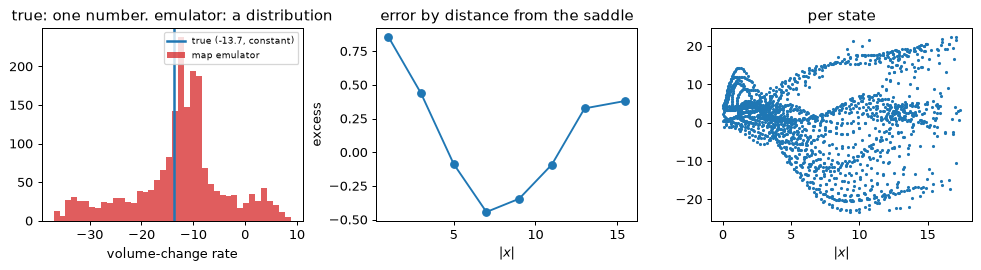

true  rate:  -13.667  std 9.1e-05
model rate:  -12.609  std 9.01e+00


In [ ]:
map_lc, map_arr = diag.local_contraction(step_map, probe)

fig, axs = plt.subplots(1, 3, figsize=(11, 3.1))
axs[0].axvline(float(lc["rate_mean"]), color="tab:blue", lw=2,
               label=f"true ({float(lc['rate_mean']):.1f}, constant)")
axs[0].hist(map_arr["rate"], bins=40, alpha=.75, label="map emulator", color="tab:red")
axs[0].set_xlabel("volume-change rate"); axs[0].legend(fontsize=7)
axs[0].set_title("true: one number. emulator: a distribution")

edges = map_arr["edges"]
mids = ((edges[:-1] + edges[1:]) / 2).tolist()
axs[1].plot(mids, map_arr["binned_excess"].tolist(), "o-")
axs[1].set_xlabel(r"$|x|$"); axs[1].set_ylabel("excess")
axs[1].set_title("error by distance from the saddle")

axs[2].plot(map_arr["abs_x"], map_arr["excess"], ".", ms=3)
axs[2].set_xlabel(r"$|x|$"); axs[2].set_title("per state")
plt.tight_layout(); plt.show()

print(f"true  rate: {float(lc['rate_mean']):+8.3f}  std {float(lc['rate_std']):.1e}")
print(f"model rate: {float(map_lc['rate_mean']):+8.3f}  std {float(map_lc['rate_std']):.2e}")

## 6. Why this happens, and the repair

Integrate the learned field over one step and expand in $\Delta t$:

$$
x_{n+1} = x_n + \Delta t\,g(x_n) + \tfrac{\Delta t^2}{2}(Dg\,g)(x_n) + \dots
$$

The divergence — the volume change — does **not appear at first order**. It enters at
$\Delta t^2$, which at $\Delta t = 0.01$ is a factor of 100 smaller than the leading term. A
training signal made of one-step increments is therefore almost blind to it.

That explains why the map emulator can be accurate and still get the volume wrong, and it
suggests the repair: use the parameterisation for which the divergence is a *measurable local
quantity*, and put it in the loss.

The two cells below train a field emulator without and with that penalty.

In [ ]:
field_plain, hist_plain = train.train("field", field_model, data, key, epochs=40, batch=256)

step_plain = train.make_step("field", train.cast(field_plain, train.DTYPE_DIAG))
div_plain = jax.vmap(lambda s: train.implied_divergence(step_plain, s))(probe[:300])
lc_plain, _ = diag.local_contraction(step_plain, probe[:1_000])

print(f"one-step MSE (float64) : {train.final_mse(data, step_plain):.5f}")
print(f"learned volume rate    : {float(div_plain.mean()):+8.3f}   (truth {lorenz.DIVERGENCE:+.3f})")
print(f"contraction ratio      : {float(lc_plain['ratio']):.3f}")

epoch   0 | mse 0.385897 | divergence penalty 0.0000


epoch  10 | mse 0.031603 | divergence penalty 0.0000


epoch  20 | mse 0.010474 | divergence penalty 0.0000


epoch  30 | mse 0.005819 | divergence penalty 0.0000


epoch  39 | mse 0.004390 | divergence penalty 0.0000


one-step MSE (float64) : 0.00432
learned volume rate    :   -0.850   (truth -13.667)
contraction ratio      : 0.046


The field emulator fits the increments well — and its volume rate is nowhere near the truth.
Changing *how* the model represents the system did not make the invariant correct; it only
changed where the freedom lives.

What it does give us is a handle: the divergence is now a cheap derivative of the output, so
it can be penalised directly.

epoch   0 | mse 0.407051 | divergence penalty 150.2924


epoch  10 | mse 0.170844 | divergence penalty 0.0042


epoch  20 | mse 0.105356 | divergence penalty 0.0028


epoch  30 | mse 0.098498 | divergence penalty 0.0052


epoch  39 | mse 0.095394 | divergence penalty 0.0044
                  one-step MSE   volume rate   contraction
map                    0.01049       -15.418         1.003


field                  0.00432        -0.850         0.046


field+penalty          0.09504       -13.604         0.995
truth                                -13.667         1.000

(all three measured on the same probe states, so the rows are comparable)

one-step MSE: field 0.0043 -> field+penalty 0.0950


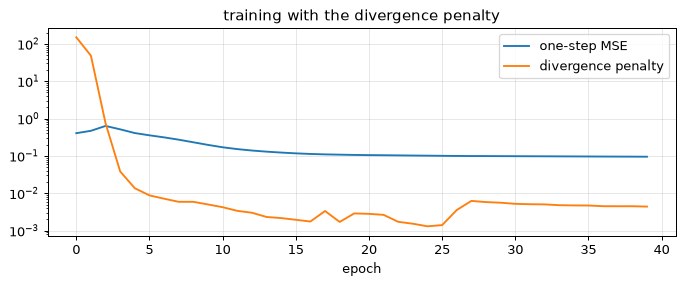

In [ ]:
field_fixed, hist_fixed = train.train("field", train.make_mlp(jax.random.PRNGKey(3), 64, 2),
                                      data, key, epochs=40, batch=256,
                                      div_weight=1.0)
step_fixed = train.make_step("field", train.cast(field_fixed, train.DTYPE_DIAG))

print(f"{'':16s}{'one-step MSE':>14s}{'volume rate':>14s}{'contraction':>14s}")
for name, st in (("map", step_map), ("field", step_plain), ("field+penalty", step_fixed)):
    div = jax.vmap(lambda s: train.implied_divergence(st, s))(probe[:300])
    lcx, _ = diag.local_contraction(st, probe[:1_000])
    print(f"{name:16s}{train.final_mse(data, st):14.5f}"
          f"{float(div.mean()):14.3f}{float(lcx['ratio']):14.3f}")
print(f"{'truth':16s}{'':14s}{lorenz.DIVERGENCE:14.3f}{1.0:14.3f}")
print("\n(all three measured on the same probe states, so the rows are comparable)")

print(f"\none-step MSE: field {train.final_mse(data, step_plain):.4f} -> "
      f"field+penalty {train.final_mse(data, step_fixed):.4f}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.semilogy([h["mse"] for h in hist_fixed], label="one-step MSE")
ax.semilogy([max(h["divergence_penalty"], 1e-8) for h in hist_fixed], label="divergence penalty")
ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("training with the divergence penalty"); plt.show()

## 7. Precision: why training is float32 and diagnostics are float64

Consumer GPUs run float64 at a fraction of float32 throughput, so training uses float32. The
diagnostics are cheap by comparison and run in float64.

This is insurance, not decoration, but it is worth being precise about what it buys. The cell
below runs the *same* spectrum calculation on the ground truth in both precisions. The sum
invariant survives both — the QR renormalisation keeps it stable — but the individual
exponents differ by a few percent, which is the same size as the differences between the
configurations in the table above. At this scale float64 costs a couple of seconds, so there
is no reason to accept that ambiguity.

In [ ]:
start = gt[0]
lam64, _ = diag.lyapunov_spectrum(gt_step, start, steps=5_000)

# the same calculation with every array explicitly float32
step32 = lambda y: lorenz.rk4_step(y.astype(jnp.float32))
lam32, _ = diag.lyapunov_spectrum(step32, start.astype(jnp.float32), steps=5_000)

print(f"{'':10s}{'float32':>12s}{'float64':>12s}{'difference':>12s}")
for i in (1, 2, 3):
    a, b = float(lam32[f"lambda_{i}"]), float(lam64[f"lambda_{i}"])
    print(f"lambda_{i}  {a:12.4f}{b:12.4f}{abs(a-b):12.4f}")
print(f"\nsum(float32) = {float(lam32['sum']):.4f}   sum(float64) = {float(lam64['sum']):.4f}"
      f"   (both should equal {lorenz.DIVERGENCE:.3f})")
print("the invariant survives both; the individual exponents differ by a few percent")

               float32     float64  difference
lambda_1        0.9164      0.8832      0.0332
lambda_2       -0.0287      0.0002      0.0289
lambda_3      -14.5542    -14.5499      0.0043

sum(float32) = -13.6666   sum(float64) = -13.6666   (both should equal -13.667)
the invariant survives both; the individual exponents differ by a few percent


## 8. What to take away

1. **One-step error does not measure dynamics.** The map emulator reached a small MSE while
   its Lyapunov spectrum and volume contraction were not close to the truth.
2. **A known invariant is the cheapest useful test.** Lorenz-63's divergence is constant, so
   the target is exact and any departure is the model's fault.
3. **Measure the distribution, not just the mean.** The emulator's typical state can be
   nearly right while a minority of states are badly wrong; a mean-only number points a fix
   at the wrong thing.
4. **You can only control what you can measure inside the model.** A map has no local
   quantity to penalise. A field exposes the divergence, and penalising it moves the
   contraction ratio back toward 1 at a modest cost in one-step accuracy.
5. **Controls and precision are part of the method.** Without the second-trajectory and
   identity columns, and without float64, the numbers above would be harder to interpret.

**Where this could go next.** The penalty uses a divergence known analytically for
Lorenz-63. The open question is estimating it when it is *not* known — from data, or from a
partially known model. [`experiments/`](experiments) carries three follow-ups on exactly
that; [`docs/PAPER.pdf`](docs/PAPER.pdf) is the full study this notebook is a reduction of.